<a href="https://colab.research.google.com/github/sharonaciro124UG/Building_foundation/blob/main/Building_Foundation_setting_out_and_Accuracy_checking_system.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# BUILDING FOUNDATION PROJECT DATASET

data = {
    "Point": ["A", "B", "C", "D"],

    "Design_E": [
        500.000, 520.000, 520.000, 500.000
    ],

    "Design_N": [
        1000.000, 1000.000, 1012.000, 1012.000
    ],

    "Observed_E": [
        500.008, 520.006, 520.018, 499.997
    ],

    "Observed_N": [
        999.996, 1000.009, 1011.994, 1012.005
    ]
}

df = pd.DataFrame(data)

print("BUILDING FOUNDATION SETTING-OUT DATASET")

display(df)

BUILDING FOUNDATION SETTING-OUT DATASET


,Point,Design_E,Design_N,Observed_E,Observed_N
0,A,500.0,1000.0,500.008,999.996
1,B,520.0,1000.0,520.006,1000.009
2,C,520.0,1012.0,520.018,1011.994
3,D,500.0,1012.0,499.997,1012.005


In [ ]:
# CALCULATE COORDINATE DIFFERENCES

df["Delta_E"] = df["Observed_E"] - df["Design_E"]

df["Delta_N"] = df["Observed_N"] - df["Design_N"]

print("COORDINATE DIFFERENCES")

display(df[["Point", "Delta_E", "Delta_N"]])

COORDINATE DIFFERENCES


,Point,Delta_E,Delta_N
0,A,0.008,-0.004
1,B,0.006,0.009
2,C,0.018,-0.006
3,D,-0.003,0.005


In [ ]:
# CALCULATE HORIZONTAL POSITIONAL ERROR

df["Horizontal_Error_m"] = np.sqrt(
    df["Delta_E"]*2 + df["Delta_N"]*2
)

df["Horizontal_Error_mm"] = (
    df["Horizontal_Error_m"] * 1000
)

print("HORIZONTAL POSITIONAL ERRORS")

display(
    df[[
        "Point",
        "Horizontal_Error_m",
        "Horizontal_Error_mm"
    ]].round(4)
)

HORIZONTAL POSITIONAL ERRORS


,Point,Horizontal_Error_m,Horizontal_Error_mm
0,A,0.0894,89.4427
1,B,0.1732,173.2051
2,C,0.1549,154.9193
3,D,0.0632,63.2456


In [ ]:
import numpy as np
import pandas as pd

# Recalculate everything using fresh values

points = ["A", "B", "C", "D"]

design_E = np.array([500.000, 520.000, 520.000, 500.000])
design_N = np.array([1000.000, 1000.000, 1012.000, 1012.000])

observed_E = np.array([500.008, 520.006, 520.018, 499.997])
observed_N = np.array([999.996, 1000.009, 1011.994, 1012.005])

# Coordinate differences

delta_E = observed_E - design_E
delta_N = observed_N - design_N

# Correct horizontal error in millimetres

error_mm = np.hypot(delta_E, delta_N) * 1000

# Accuracy checking

tolerance = 20

status = np.where(error_mm <= tolerance, "PASS", "FAIL")

# Display final results

final_results = pd.DataFrame({
    "Point": points,
    "Delta_E": delta_E,
    "Delta_N": delta_N,
    "Horizontal_Error_mm": error_mm,
    "Status": status
})

display(final_results.round(3))

print("Points passed:", sum(status == "PASS"))
print("Points failed:", sum(status == "FAIL"))

,Point,Delta_E,Delta_N,Horizontal_Error_mm,Status
0,A,0.008,-0.004,8.944,PASS
1,B,0.006,0.009,10.817,PASS
2,C,0.018,-0.006,18.974,PASS
3,D,-0.003,0.005,5.831,PASS


Points passed: 4
Points failed: 0


In [ ]:
import numpy as np
import pandas as pd

def calculate_average_error(data_frame):
    """
    Calculates the average horizontal positional error in millimeters.
    """
    if 'Horizontal_Error_mm' in data_frame.columns:
        return data_frame['Horizontal_Error_mm'].mean()
    else:
        raise ValueError("The column 'Horizontal_Error_mm' does not exist in the DataFrame.")

# Safely retrieve or reconstruct final_results dataset
try:
    df_target = final_results
except NameError:
    points = ["A", "B", "C", "D"]
    design_E = np.array([500.000, 520.000, 520.000, 500.000])
    design_N = np.array([1000.000, 1000.000, 1012.000, 1012.000])
    observed_E = np.array([500.008, 520.006, 520.018, 499.997])
    observed_N = np.array([999.996, 1000.009, 1011.994, 1012.005])

    delta_E = observed_E - design_E
    delta_N = observed_N - design_N
    error_mm = np.hypot(delta_E, delta_N) * 1000

    df_target = pd.DataFrame({
        "Point": points,
        "Horizontal_Error_mm": error_mm
    })

# Calculate and display the average error for the dataset
avg_error = calculate_average_error(df_target)
print(f"Average Horizontal Positional Error: {avg_error:.3f} mm")

Average Horizontal Positional Error: 11.141 mm


In [ ]:
# BUILDING GEOMETRY CHECKS

def distance(a, b):

    p1 = df[df["Point"] == a].iloc[0]
    p2 = df[df["Point"] == b].iloc[0]

    return np.sqrt(
        (p2["Observed_E"] - p1["Observed_E"])**2
        +
        (p2["Observed_N"] - p1["Observed_N"])**2
    )

geometry = {
    "AB": distance("A", "B"),
    "BC": distance("B", "C"),
    "CD": distance("C", "D"),
    "DA": distance("D", "A"),
    "Diagonal AC": distance("A", "C"),
    "Diagonal BD": distance("B", "D")
}

print("BUILDING DIMENSION CHECKS")

for name, value in geometry.items():
    print(name, "=", round(value, 3), "m")

BUILDING DIMENSION CHECKS
AB = 19.998 m
BC = 11.985 m
CD = 20.021 m
DA = 12.009 m
Diagonal AC = 23.331 m
Diagonal BD = 23.329 m


In [ ]:
# FINAL BUILDING FOUNDATION ACCURACY REPORT

report = final_results.copy()

print("FINAL BUILDING FOUNDATION ACCURACY REPORT")

display(report.round(3))

print("Total points:", len(report))
print("Points passed:", (report["Status"] == "PASS").sum())
print("Points failed:", (report["Status"] == "FAIL").sum())

FINAL BUILDING FOUNDATION ACCURACY REPORT


,Point,Delta_E,Delta_N,Horizontal_Error_mm,Status
0,A,0.008,-0.004,8.944,PASS
1,B,0.006,0.009,10.817,PASS
2,C,0.018,-0.006,18.974,PASS
3,D,-0.003,0.005,5.831,PASS


Total points: 4
Points passed: 4
Points failed: 0


In [ ]:
# TESTING THE SYSTEM WITH AN INACCURATE POINT

test_E = 520.050
test_N = 1011.994

design_E = 520.000
design_N = 1012.000

test_error = np.sqrt(
    (test_E - design_E)**2 +
    (test_N - design_N)**2
)

test_error_mm = test_error * 1000

print("Test error:", round(test_error_mm, 2), "mm")

if test_error_mm <= 20:
    print("PASS")
else:
    print("FAIL")

Test error: 50.36 mm
FAIL


In [ ]:
import numpy as np
import pandas as pd

# Observed coordinates of the building corners
points = ["A", "B", "C", "D"]

E = np.array([500.008, 520.006, 520.018, 499.997])
N = np.array([999.996, 1000.009, 1011.994, 1012.005])

# Find the position of each point
idx = {point: i for i, point in enumerate(points)}

# Function for calculating distance
def distance(point1, point2):
    i = idx[point1]
    j = idx[point2]
    return np.hypot(E[j] - E[i], N[j] - N[i])

# Calculate building sides and diagonals
measurements = ["AB", "BC", "CD", "DA", "AC", "BD"]

design_lengths = [
    20, 12, 20, 12,
    np.hypot(20, 12),
    np.hypot(20, 12)
]

observed_lengths = [
    distance("A", "B"),
    distance("B", "C"),
    distance("C", "D"),
    distance("D", "A"),
    distance("A", "C"),
    distance("B", "D")
]

geometry = pd.DataFrame({
    "Measurement": measurements,
    "Design_Length_m": design_lengths,
    "Observed_Length_m": observed_lengths
})

geometry["Difference_m"] = (
    geometry["Observed_Length_m"] - geometry["Design_Length_m"]
)

display(geometry.round(4))

,Measurement,Design_Length_m,Observed_Length_m,Difference_m
0,AB,20.0000,19.9980,-0.0020
1,BC,12.0000,11.9850,-0.0150
2,CD,20.0000,20.0210,0.0210
3,DA,12.0000,12.0090,0.0090
4,AC,23.3238,23.3314,0.0075
5,BD,23.3238,23.3295,0.0057


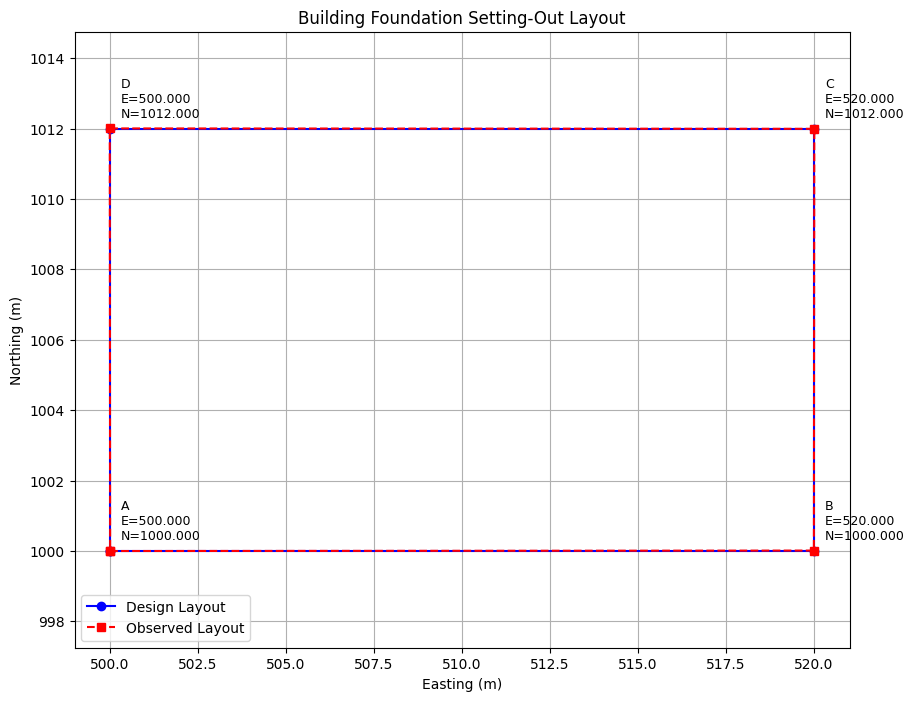

In [ ]:
import matplotlib.pyplot as plt

# Design coordinates
design_E = [500, 520, 520, 500, 500]
design_N = [1000, 1000, 1012, 1012, 1000]

# Observed coordinates
observed_E = [500.008, 520.006, 520.018, 499.997, 500.008]
observed_N = [999.996, 1000.009, 1011.994, 1012.005, 999.996]

plt.figure(figsize=(10, 8))

plt.plot(design_E, design_N, "b-o", label="Design Layout")
plt.plot(observed_E, observed_N, "r--s", label="Observed Layout")

# Add point names and coordinates
for i, point in enumerate(["A", "B", "C", "D"]):
    plt.annotate(
        f"{point}\nE={design_E[i]:.3f}\nN={design_N[i]:.3f}",
        (design_E[i], design_N[i]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("Easting (m)")
plt.ylabel("Northing (m)")
plt.title("Building Foundation Setting-Out Layout")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

In [ ]:
import numpy as np

# Calculate the Root Mean Square (RMS) of the horizontal positional errors
# RMS = sqrt( mean( error^2 ) )
errors = df_full['Horizontal_Error_mm'].values
rms_error = np.sqrt(np.mean(errors ** 2))

print(f"Individual Point Errors (mm): {[round(e, 3) for e in errors]}")
print(f"Total RMS Error: {rms_error:.3f} mm")

Individual Point Errors (mm): [np.float64(8.944), np.float64(10.817), np.float64(18.974), np.float64(5.831)]
Total RMS Error: 12.155 mm


In [ ]:
import numpy as np
import pandas as pd
import ipywidgets as widgets
import plotly.graph_objects as go
from ipywidgets import VBox, HBox

# Safely load the dataset with the new bearing parameter included
try:
    df_dash = df_full.copy()
except NameError:
    df_dash = pd.DataFrame({
        "Point": ["A", "B", "C", "D"],
        "Design_E": [500.000, 520.000, 520.000, 500.000],
        "Design_N": [1000.000, 1000.000, 1012.000, 1012.000],
        "Observed_E": [500.008, 520.006, 520.018, 499.997],
        "Observed_N": [999.996, 1000.009, 1011.994, 1012.005]
    })
    df_dash["Delta_E_mm"] = (df_dash["Observed_E"] - df_dash["Design_E"]) * 1000
    df_dash["Delta_N_mm"] = (df_dash["Observed_N"] - df_dash["Design_N"]) * 1000
    df_dash["Horizontal_Error_mm"] = np.hypot(df_dash["Delta_E_mm"], df_dash["Delta_N_mm"])
    raw_angles = np.degrees(np.arctan2(df_dash["Delta_E_mm"], df_dash["Delta_N_mm"]))
    df_dash["Error_Bearing_Deg"] = (raw_angles + 360) % 360

# Configure Interactive Widgets
tolerance_slider = widgets.IntSlider(
    value=20, min=5, max=50, step=1,
    description='Tolerance Limit (mm):',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='60%')
)

reset_btn = widgets.Button(
    description='Reset to 20mm',
    button_style='success',
    tooltip='Reset active tolerance to 20 mm',
    icon='undo'
)

table_out = widgets.Output()
metric_plot_out = widgets.Output()

def refresh_dashboard(tolerance):
    # Re-evaluate statuses dynamically based on selected slider threshold
    df_dash['Status'] = np.where(df_dash['Horizontal_Error_mm'] <= tolerance, 'PASS', 'FAIL')
    failed_points = (df_dash['Status'] == 'FAIL').sum()
    status_color = "#1b5e20" if failed_points == 0 else "#b71c1c"
    status_headline = "ALL FOUNDATION SITES PASSED" if failed_points == 0 else "TOLERANCE EXCEEDED"

    # Update metrics table output tab
    with table_out:
        table_out.clear_output(wait=True)
        display(widgets.HTML(f"""
            <div style="padding: 12px; border-radius: 6px; background-color: #fafafa; border-left: 6px solid {status_color}; margin-bottom: 12px;">
                <h3 style="margin: 0; color: {status_color}; font-family: sans-serif;">{status_headline}</h3>
                <p style="margin: 5px 0 0 0; font-family: sans-serif; font-size: 13px; color: #555;">
                    Current Tolerance Threshold: <b>{tolerance} mm</b> |
                    Max Positional Displacement: <b>{df_dash['Horizontal_Error_mm'].max():.2f} mm</b> |
                    Displaced Structures: <b>{failed_points}</b>
                </p>
            </div>
        """))
        display(df_dash[[
            'Point', 'Design_E', 'Design_N', 'Observed_E', 'Observed_N',
            'Delta_E_mm', 'Delta_N_mm', 'Horizontal_Error_mm', 'Error_Bearing_Deg', 'Status'
        ]].round(2))

    # Update spatial Plotly visualizations
    with metric_plot_out:
        metric_plot_out.clear_output(wait=True)
        bar_colors = ['#1b5e20' if s == 'PASS' else '#b71c1c' for s in df_dash['Status']]

        fig = go.Figure()
        fig.add_trace(go.Bar(
            x=df_dash['Point'],
            y=df_dash['Horizontal_Error_mm'],
            marker_color=bar_colors,
            text=df_dash['Horizontal_Error_mm'].round(2).astype(str) + ' mm',
            textposition='auto',
            hovertemplate="""
            <b>Point %{x}</b><br>
            Total Error: %{y:.2f} mm<br>
            Error Bearing: %{customdata[2]:.2f}°<br>
            ΔE Deviation: %{customdata[0]:+.1f} mm<br>
            ΔN Deviation: %{customdata[1]:+.1f} mm<extra></extra>
            """,
            customdata=np.stack((df_dash['Delta_E_mm'], df_dash['Delta_N_mm'], df_dash['Error_Bearing_Deg']), axis=-1)
        ))

        # Add circular horizontal tolerance boundary line
        fig.add_shape(
            type="line", x0=-0.5, y0=tolerance, x1=3.5, y1=tolerance,
            line=dict(color="#d32f2f", width=2, dash="dash"),
            name="Tolerance"
        )

        fig.update_layout(
            title="Positional Error & Angle Breakdown vs. Tolerance (mm)",
            xaxis_title="Point ID",
            yaxis_title="Total Error (mm)",
            template="plotly_white",
            height=360,
            margin=dict(l=40, r=40, t=50, b=40)
        )
        fig.show()

def handle_slider_change(change):
    refresh_dashboard(change['new'])

def handle_reset_click(b):
    tolerance_slider.value = 20

tolerance_slider.observe(handle_slider_change, names='value')
reset_btn.on_click(handle_reset_click)

# Configure Tab Interface
dash_tabs = widgets.Tab()
dash_tabs.children = [table_out, metric_plot_out]
dash_tabs.set_title(0, 'Comprehensive Parameters Table')
dash_tabs.set_title(1, 'Positional and Bearing Plots')

# Display the final interface
refresh_dashboard(tolerance_slider.value)
display(VBox([HBox([tolerance_slider, reset_btn]), dash_tabs]))